In [1]:
### my stuff ###
import sys
sys.path.append('../calculations/')
from consts import *
from functions import *
from physics_functions import *

### python stuff ###
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as tk
from scipy.optimize import curve_fit
import scipy.stats as stats
import scipy.misc as misc
import scipy.special as sp
from scipy import integrate as spInt
from scipy.interpolate import interp1d

### Notes ###

<u> Morozov 2010 </u>
* for 0.5 Bar the UV flux is 10% higher than 1bar, but visible is basically zero. 
* 1bar fluctuations in vis are statistical (minimal collection efficiency)
* main method is broadband data

***
#### things done ####
* some data was negative (from webplot digitizer?)

* multiply morozov UV by 10%

In [2]:
### loading data ###

#gern data gives a yield
gern_x, gern_y = np.loadtxt("./literature_data/gernhauser_cf4_05bar_spikes.csv", skiprows = 2, delimiter = ",", unpack = True)
# gern_x, gern_y = np.loadtxt("./literature_data/gernhauser_cf4_05bar_spikes.csv", skiprows = 2, delimiter = ",", unpack = True)
gern_x_ar, gern_y_ar = np.loadtxt("./literature_data/gernhauser_gar_05bar.csv", skiprows = 2, delimiter = ",", unpack = True)

#reorder gernhauser data
gern_x, gern_y = zip( *sorted( zip(gern_x, gern_y) ) )
#make all gernhauser data > 0
gern_y = np.array([x if x >= 0. else 0 for x in gern_y])

# spectrum2 has the y values as yield in ph/MeV/nm
mor_x_1bar, mor_y_1bar = np.genfromtxt("./literature_data/morozov_2010_spectrum2.csv", skip_header = 2,  usecols = (0,1), delimiter = ",", unpack = True)
mor_x_5bar, mor_y_5bar = np.genfromtxt("./literature_data/morozov_2010_spectrum2.csv", skip_header = 2,  usecols = (2,3), delimiter = ",", unpack = True)

# remove NANs from array?
mor_x_1bar = mor_x_1bar[np.logical_not(np.isnan(mor_x_1bar))]
mor_y_1bar = mor_y_1bar[np.logical_not(np.isnan(mor_y_1bar))]
# filter(lambda v: v==v, x) other option for handling NANs

#making all morozov data positivee
mor_y_1bar = np.array([x if x > 0. else 0 for x in mor_y_1bar])
mor_y_5bar = np.array([x if x > 0. else 0 for x in mor_y_5bar])

ipGern_raw = interp1d(gern_x, gern_y, kind = 'cubic')
ipMor1_raw = interp1d(mor_x_1bar, mor_y_1bar, kind = 'cubic')
ipMor5_raw = interp1d(mor_x_5bar, mor_y_5bar, kind = 'cubic')

# PDE data from "https://hub.hamamatsu.com/sp/hc/resources/SiPM_SPAD_%20Emerging_Applications.pdf"
pde_x, pde_y = np.genfromtxt("./literature_data/vuv4_PDE_ham1.csv", skip_header = 2, usecols = (0, 1), delimiter = ",", unpack = True)
pde_y = pde_y/100
# pde_x, pde_y = zip( *sorted( zip(pde_x, pde_y) ) ) # reorded pde data
ipPDE = interp1d(pde_x[0:-2], pde_y[0:-2], kind = "cubic")

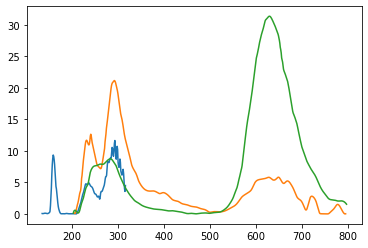

In [3]:
waves_gern = np.arange(min(gern_x), max(gern_x), 1)
waves_mor1 = np.arange(min(mor_x_1bar), max(mor_x_1bar), 1)
waves_mor5 = np.arange(min(mor_x_5bar), max(mor_x_5bar), 1)

plt.plot(waves_gern, ipGern_raw(waves_gern))
plt.plot(waves_mor1, ipMor1_raw(waves_mor1))
plt.plot(waves_mor5, ipMor5_raw(waves_mor5))

# plt.ylim(-0.05, 0.04)

In [4]:
# getting yield ratios between gern and morozov
firstW = min(mor_x_1bar)
lastW = max(gern_x)

a = spInt.quad(ipMor1_raw, firstW, lastW, limit = 200, epsabs = 0.1)
b = spInt.quad(ipGern_raw, firstW, lastW, limit = 300, epsabs = 0.1)

ratio1 = a[0]/b[0]# ratio of mor/gernn for overlapping range
ratio2 = ratio1 * 1.1 #1.1 factor for 10% UV extra in morozov going from 1bar to 05bar

In [5]:
# should repeat scaling calculations by comparing Gern's argon yield

'''
deapPDE = AlphaYield_deap / LAr absolute yield for alphas
Gar yield = pietro's deap LY / deapPDE

compare this with gern's
pietro: In liquid the LY for 222Rn in deap was 8.12 PE/keV.
'''

"\ndeapPDE = AlphaYield_deap / LAr absolute yield for alphas\nGar yield = pietro's deap LY / deapPDE\n\ncompare this with gern's\npietro: In liquid the LY for 222Rn in deap was 8.12 PE/keV.\n"

In [6]:
# VUV yields
Yvuv_05bar = spInt.quad(ipGern_raw, min(gern_x), 180, limit = 200, epsabs = 0.1)[0]
Yvuv_05bar_scaled = ratio2*Yvuv_05bar

print("VUV yield, 0.5 bar =", Yvuv_05bar)
print("VUV yield, 0.5 bar, Mor corrected =", Yvuv_05bar_scaled)

VUV yield, 0.5 bar = 98.25761405412402
VUV yield, 0.5 bar, Mor corrected = 247.17159914754566


In [7]:
# UV yield 05bar, 200nm to 500nm
xminMor = min(mor_x_1bar)
Yuv_1 = spInt.quad(ipMor1_raw, xminMor, 500, limit = 200, epsabs = 0.1)[0]
Yuv_05 = 1.1 * Yuv_1
Yuv_5 = spInt.quad(ipMor5_raw, min(mor_x_5bar), 500, limit = 200, epsabs = 0.1)[0]
print("UV yield, 0.5 bar", Yuv_05)
print("UV yield, 5 bar", Yuv_5)

UV yield, 0.5 bar 2052.5164272353604
UV yield, 5 bar 795.3504207113564


In [8]:
# visible yields
Yvis_1 = spInt.quad(ipMor1_raw, 500, max(mor_x_1bar), limit = 200)[0]
Yvis_5 = spInt.quad(ipMor5_raw, 500, max(mor_x_5bar), limit = 200)[0]
print("vis yield, 1 bar =", Yvis_1)
print("vis yield, 5 bar =", Yvis_5)

vis yield, 1 bar = 742.7856874190007
vis yield, 5 bar = 3436.3111598612936


In [9]:
# loading filter data #
lp500x, lp500y = np.genfromtxt("./filters/LP_500nm.csv", skip_header = 1, usecols = (0, 1), delimiter = ",", unpack = True)
lp500y = lp500y/100
lp225x, lp225y = np.genfromtxt("./filters/lp_225_better.csv", skip_header = 1, usecols = (0, 1), delimiter = ",", unpack = True)

ip500 = interp1d(lp500x, lp500y, kind = 'linear')
ip225 = interp1d(lp225x, lp225y, kind = 'linear')

In [10]:
## make complete spectrum ##

# ** currently scaling VUV yield the same as UV yield ** #

#get decrease in UV spectrum from 1 bar to 5 bar
#divide VUV spectrum by this amount, and multiply by other scaling factor
mUVScale = Yuv_1/Yuv_5
scale_gVUV_to5bar = ratio2 / mUVScale

igern_max = next(x[0] for x in enumerate(gern_x) if x[1] > min(mor_x_5bar))

fullx = np.array(list(gern_x[0:igern_max]) + list(mor_x_5bar))
fully = np.array(list(scale_gVUV_to5bar * gern_y[0:igern_max]) + list(mor_y_5bar))

minX = min(fullx)
maxX = max(fullx)
wavesFull = np.arange(min(fullx), max(fullx), 1)
# waveFull_1bar
ipFull = interp1d(fullx, fully, kind = "cubic")

In [11]:
# functions
def fspecPDE(x):
    return ipPDE(x) * ipFull(x)

def fspec500(x):
    return fspecPDE(x) * ip500(x)

def fspec225(x):
    return fspecPDE(x) * ip225(x)

def myGaussian(x, mean, FWHM):
    c = FWHM/2.355
    return np.exp((-(x - mean)**2)/(2*c**2))

def fspecBP160(x):
    gauss = myGaussian(x, 160, 20)
    return gauss*fspecPDE(x)

In [12]:
## signal strengths
#bare = VUV + UV + vis
#500 lp = vis
#225 lp = UV + vis
#160 bp = VUV

yBare = spInt.quad(fspecPDE, minX, maxX, limit = 300, epsabs = 1)

y500 = spInt.quad(fspecPDE, 500, maxX, limit = 300, epsabs = 1)
ylp500 = spInt.quad(fspec500, 200, maxX, limit = 300, epsabs = 1)

y225 = spInt.quad(fspecPDE, 225, maxX, limit = 300, epsabs = 1)
ylp225 = spInt.quad(fspec225, 200, maxX, limit = 300, epsabs = 10)

y200_225Missed = spInt.quad(fspecPDE, 180, 225, limit = 300, epsabs = 1)

measured_dif160 = yBare[0] - ylp225[0]

y160 = spInt.quad(fspecPDE, minX, 180, limit = 300, epsabs = .1)
ybp160 = spInt.quad(fspecBP160, minX, 200, limit = 300, epsabs = 0.1)

print("full yield = ", yBare[0], "ph/MeV \n")

print("500nm+ yield = ",y500[0], "ph/MeV")
print("500nm longpass yield = ",ylp500[0], "ph/MeV")
lp500Loss = y500[0] - ylp500[0]
print("500nm lp loss = ", lp500Loss, "ph/MeV \n")

print("225nm+ yield = ", y225[0], "ph/MeV")
print("225nm longpass yield = ", ylp225[0], "ph/MeV")
lp225Loss = y225[0] - ylp225[0]
print("lp225loss = ", lp225Loss, "ph/MeV \n")

print("VUV extrapolation")
print("measured = bare - lp 225nm = ", measured_dif160)
print("vuvDif = measured - lp225loss =", measured_dif160 - lp225Loss ,  " = trueVUV + true180_225")

print("true 140-180nm = ", y160[0], "ph/MeV")
print("true 180-225 = ", y200_225Missed[0] ,"ph/MeV \n")

YvuvBP = .15 * ybp160[0]
print("160nm bandpass, 15% transmission yield = ", YvuvBP, "ph/MeV")

full yield =  1077.6927244070253 ph/MeV 

500nm+ yield =  889.2303016305606 ph/MeV
500nm longpass yield =  860.4802908156357 ph/MeV
500nm lp loss =  28.75001081492485 ph/MeV 

225nm+ yield =  1049.7973383449237 ph/MeV
225nm longpass yield =  973.6970376942437 ph/MeV
lp225loss =  76.10030065067997 ph/MeV 

VUV extrapolation
measured = bare - lp 225nm =  103.99568671278155
vuvDif = measured - lp225loss = 27.89538606210158  = trueVUV + true180_225
true 140-180nm =  24.00803178755783 ph/MeV
true 180-225 =  3.8081370860873847 ph/MeV 

160nm bandpass, 15% transmission yield =  3.169612113043146 ph/MeV


In [13]:
# signal strength
#A - use 225nm longpass

NvuvA = yBare[0] - ylp225[0] - lp225Loss - y200_225Missed[0]

print("agrees? ", NvuvA - y160[0] < 0.1)
print(NvuvA)

#B - use 160nm bandpass
NvuvB = YvuvBP

agrees?  True
24.087248976014195


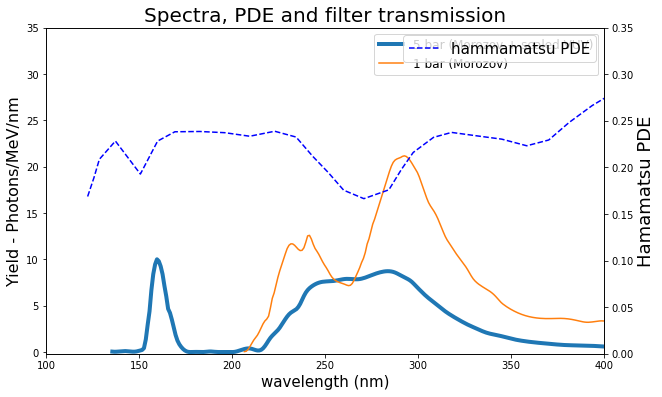

In [17]:
fig, ax = plt.subplots(figsize = (10, 6))
specScale = 100/max(ipFull(wavesFull))
specScale = 1

ax.plot(wavesFull, ipFull(wavesFull) * specScale, label = "5 bar (Morozov + scaled VUV)", linewidth = 4)
ax.plot(wavesFull[71:-5], ipMor1_raw(wavesFull[71:-5]), label = "1 bar (Morozov)", linestyle = "-")

# ax.plot(waves_gern, ipGern_raw(waves_gern), color = 'r')
# plt.plot(lp225x, 100*lp225y, label = "225nm longpass filer")
# plt.plot(lp500x, 100*lp500y)

ax2 = ax.twinx()
ax2.plot(pde_x[0:-2], 1*pde_y[0:-2], label = "hammamatsu PDE", color = 'b', linestyle = "--")
ax2.set_ylabel("Hamamatsu PDE", fontsize = 18)
ax2.legend(fontsize = 15, loc = "upper right")

ax2.set_ylim(0, 0.35)

ax.set_title("Spectra, PDE and filter transmission", fontsize = 20)
ax.set_xlabel("wavelength (nm)", fontsize = 15)
#plt.ylabel("PDE or Transmittance (%)", fontsize = 15)
ax.set_ylabel("Yield - Photons/MeV/nm", fontsize = 16)
ax.legend(fontsize = 12)
ax.set_xlim(100, 400)
ax.set_ylim(-0.2, 35)

plt.savefig("g4_spectra.png")
plt.show()